# Supplemental Figure 2, Panel F

Comparison of feature importance metrics from all-cRE models trained using BAF-dep from different BAFinh doses Bottom half of each plot grid is pairwise scatter of MDI or ridge regression coefficients, top half is heatmap of Pearson r for correlation between metrics. Model performance (AUROC) for each dose is indicated.

*Output: PanelF.pdf* 

# Setup

In [1]:
#load packages
library(tidyverse)
library(patchwork)
library(ggrastr)
library(RColorBrewer)
theme_set(theme_bw() + theme(panel.grid=element_blank()))
library(gridExtra)
library(here)
here::i_am("figures/SuppFig2/PanelF/PanelF.ipynb")

sessionInfo()

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine


here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/figures/SuppFig2/PanelF

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] here_1.0.2         gridExtra_2.3      RColorBrewer_1.1-3 ggrastr_1.0.2     
 [5] patchwork_1.3.0    lubridate_1.9.4    forcats_1.0.0      stringr_1.5.1     
 [9] dplyr_1.1.4        purrr_1.0.2        readr_2.1.5        tidyr_1.3.1       
[13] tibble_3.2.1       ggplot2_3.5.2      tidyvers

# Load data

In [2]:
# read in feature importances for model run on different DAR sets (varying BAFinh dose)

dat_10nM <- read.delim(
  here(
    "inputs", "ReModEx", "GM12878", "all_cRE",
    "dose_10nM", "feature_importance.csv"
  ),
  sep = ","
) %>%
  arrange(feature)

dat_100nM <- read.delim(
  here(
    "inputs", "ReModEx", "GM12878", "all_cRE",
    "dose_100nM", "feature_importance.csv"
  ),
  sep = ","
) %>%
  arrange(feature)

dat_1uM <- read.delim(
  here(
    "inputs", "ReModEx", "GM12878", "all_cRE",
    "dose_1uM", "feature_importance.csv"
  ),
  sep = ","
) %>%
  arrange(feature)

dat_10uM <- read.delim(
  here(
    "inputs", "ReModEx", "GM12878", "all_cRE",
    "dose_10uM", "feature_importance.csv"
  ),
  sep = ","
) %>%
  arrange(feature)

dat_0.5h <- read.delim(
  here(
    "inputs", "ReModEx", "GM12878", "all_cRE",
    "time_0.5h", "feature_importance.csv"
  ),
  sep = ","
) %>%
  arrange(feature)

dat_1h <- read.delim(
  here(
    "inputs", "ReModEx", "GM12878", "all_cRE",
    "time_1h", "feature_importance.csv"
  ),
  sep = ","
) %>%
  arrange(feature)

dat_2h <- read.delim(
  here(
    "inputs", "ReModEx", "GM12878", "all_cRE",
    "time_2h", "feature_importance.csv"
  ),
  sep = ","
) %>%
  arrange(feature)

dat_24h <- read.delim(
  here(
    "inputs", "ReModEx", "GM12878", "all_cRE",
    "time_24h", "feature_importance.csv"
  ),
  sep = ","
) %>%
  arrange(feature)


# Generate plots

In [3]:

#pairwise scatter of Ridge coefs between all doses, as well as correlation between Ridge coefficients

plots_MDI <- list()
all_dat <- list(dat_10nM, dat_100nM, dat_1uM, dat_10uM)
labels <- c("10nM", "100nM", "1uM", "10uM")

for (i in 1:4) {
    rowplot <- list()
  
    for (j in 1:4) {
        if (i == j) {
          plot <- ggplot() + theme_void()
      
        } else if (j < i) {
            lims <- c(0,0.12)
            plot <- ggplot(data = data.frame(y = all_dat[[i]]$MDI_importance,
                                           x = all_dat[[j]]$MDI_importance),
                         aes(x = x, y = y)) +
            rasterize(geom_point(size=.5), dpi=300) + 
            geom_smooth(method=lm, se=F, color="firebrick", linewidth=.5) + 
            xlab(labels[j]) + ylab(labels[i]) +
            coord_fixed(ratio = 1, xlim=lims, ylim=lims) +
            scale_x_continuous(breaks=c(0,0.05,0.1)) + scale_y_continuous(breaks=c(0,0.05,0.1))


        } else {
            cor_val <- cor(all_dat[[j]]$MDI_importance, all_dat[[i]]$MDI_importance, use = "complete.obs")
            plot <- ggplot(data = data.frame(x = 1, y = 1, value = cor_val),
                         aes(x = x, y = y)) +
            geom_tile(aes(fill = value)) +
            scale_fill_gradient2(low = "white", high = "firebrick", limits = c(0, 1)) +
            geom_text(aes(label = format(value, digits=3))) + xlab(labels[j]) + ylab(labels[i]) + coord_fixed() + 
            theme(axis.text = element_blank(), axis.ticks = element_blank())
            }
    
    rowplot[[j]] <- plot
    }
  
    plots_MDI[[i]] <- rowplot
}

In [4]:
#same as above but for MDI coefs
plots_Ridge <- list()
all_dat <- list(dat_10nM, dat_100nM, dat_1uM, dat_10uM)
labels <- c("dat_10nM", "dat_100nM", "dat_1uM", "dat_10uM")

for (i in seq_along(labels)) {
    rowplot <- list()
  
    for (j in seq_along(labels)) {
        if (i == j) {
          plot <- ggplot() + theme_void()
      
        } else if (j < i) {
            lims <- c(-0.1,0.2)
            plot <- ggplot(data = data.frame(x = all_dat[[i]]$Ridge_coef,
                                           y = all_dat[[j]]$Ridge_coef),
                         aes(x = x, y = y)) +
            rasterize(geom_point(size=.5), dpi=300) + 
            geom_smooth(method=lm, se=F, color="firebrick", linewidth=.5) + 
            xlab(labels[j]) + ylab(labels[i]) +
            coord_fixed(ratio = 1, xlim=lims, ylim=lims) +
            scale_x_continuous(breaks=c(-0.1,0,0.1)) + scale_y_continuous(breaks=c(-0.1,0,0.1))

        } else {
            cor_val <- cor(all_dat[[j]]$Ridge_coef, all_dat[[i]]$Ridge_coef, use = "complete.obs")
            plot <- ggplot(data = data.frame(x = 1, y = 1, value = cor_val),
                         aes(x = x, y = y)) +
            geom_tile(aes(fill = value)) +
            scale_fill_gradient2(low = "white", high = "firebrick", limits = c(0, 1)) +
            geom_text(aes(label = format(value, digits=3))) + ylab(labels[j]) + xlab(labels[i]) + coord_fixed()  + 
            theme(axis.text = element_blank(), axis.ticks = element_blank())
            }
    
    rowplot[[j]] <- plot
    }
  
    plots_Ridge[[i]] <- rowplot
}

# Assemble figure panel

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
Saving 12 x 7 in image
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


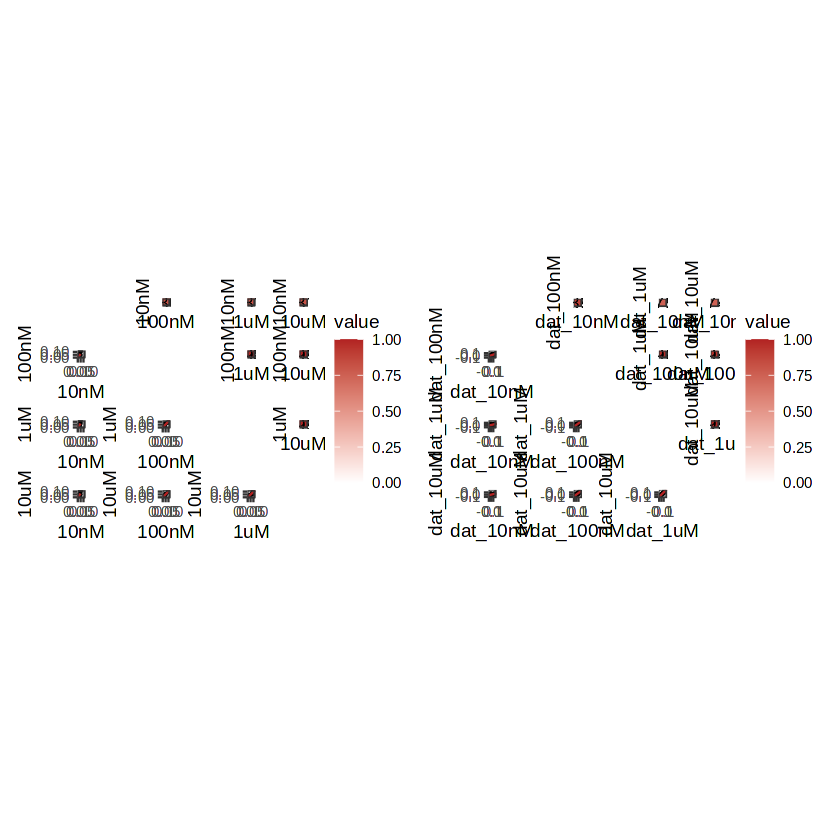

In [5]:
p1 <- (wrap_plots(plotlist = unlist(plots_MDI, recursive = FALSE), ncol = 4) +
    plot_layout(guides = "collect") & theme(legend.position = "right")) 
p2 <- (wrap_plots(plotlist = unlist(plots_Ridge, recursive = FALSE), ncol = 4) +
    plot_layout(guides = "collect") & theme(legend.position = "right")) 

p1 | p2
ggsave("PanelF.pdf", width=12)